# 6. Simulating the network day by day

**Goal of this notebook:** check whether the six-center network still delivers its promised savings and speed when it runs one order at a time, with all the randomness a real operation has.

Notebooks 2 to 5 reason with yearly totals and weekly averages. A real fulfillment network deals with individual orders. Carriers are late on some days and early on others. Replenishment trucks arrive when they arrive. Black Friday brings six times a normal day's orders in one day. And a center only helps for products it actually holds in stock.

This notebook is a **discrete-event simulation**: the real order stream of the study year is replayed item by item through the network of notebook 2, run with the inventory policy of notebook 3. Every order, every daily picking wave and every replenishment truck is an event on a clock. The code is in `src/simulation.py` and uses the SimPy library.

What happens to each item a customer orders:

1. If the customer's city is not served by a center, or the item's category is not one the center stocks, the seller ships it direct, as today.
2. If the center has the item in stock, it joins that center's picking queue. Each day the center picks up to its daily capacity, oldest orders first. The parcel then spends a random number of days with the carrier, drawn from real transit times for that distance zone.
3. If the center is out of stock, the seller ships it direct.

Every Monday each center updates its forecast for each category it stocks and orders enough to bring stock on hand plus stock on order up to the order-up-to level of notebook 3. The truck arrives after a random lead time.

Items that ship direct keep their real purchase-to-door time from the data, so the "today" numbers below are exactly what happened.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import network_model as nm
import simulation as sim
from helpers import COLORS, RESULTS, save_figure, set_chart_style

set_chart_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

data = nm.prepare()
print(f"{len(data.ship):,} items in the study year")

84,523 items in the study year


## Step 1. The assumptions of the simulation

The simulation needs a few numbers the data does not contain:

In [2]:
sim.Settings()

Settings(start='2017-10-02', end='2018-08-20', service_level=0.95, lead_days=(4, 7, 12), capacity_headroom=0.3, stocked='policy', seed=0)

- **Window.** It runs from 2 October 2017 to 20 August 2018. September is used to start the forecasts, and the data thins out after 20 August.
- **Lead time.** A replenishment truck takes between 4 and 12 days, most often 7, matching the one-week lead time assumed in notebook 3 but with variation.
- **Picking capacity.** Each center can pick 30% more items per day than its average daily volume. Below, this is varied to see what happens at Black Friday.
- **What is stocked.** Each center holds the 10 categories that notebook 3 planned for, at a 95% service level.

## Step 2. One simulated year

In [3]:
items, daily = sim.run(data, sim.Settings())
base = sim.summarize(items)

routes = items["route"].value_counts()
print("Where the items went:")
print((100 * routes / len(items)).round(1).astype(str) + "%")

headline = pd.DataFrame({
    "today (what happened)": [base["door_days_today"], base["p90_door_today"], base["within_5_days_today_pct"],
                              base["freight_today"]],
    "six centers, simulated": [base["door_days_sim"], base["p90_door_sim"], base["within_5_days_sim_pct"],
                               base["freight_sim"]],
}, index=["average days from purchase to door", "90th percentile days", "delivered within 5 days (%)",
          "freight (R$)"])
print(f"\nFreight saving: {base['saving_pct']:.1f}%   Fill rate at the centers: {base['fill_rate_pct']:.1f}%")
headline

Where the items went:
route
center                          43.9%
direct: category not stocked    27.1%
direct: city not served         25.6%
direct: stockout                 3.3%
Name: count, dtype: str

Freight saving: 7.1%   Fill rate at the centers: 92.9%


,today (what happened),"six centers, simulated"
average days from purchase to door,12.71,9.39
90th percentile days,24.02,20.07
delivered within 5 days (%),14.65,37.51
freight (R$),"1,579,600.18","1,467,133.73"


**What this shows.** Measured the way a customer feels it, from purchase to door, orders arrive in about 9.4 days instead of 12.7, and the share delivered within five days rises from 15% to 37%. That is a bigger gain than notebook 2's transit-only measure suggested, because an item shipped from a center's stock skips the seller's own handling time, which averages several days.

But the freight saving is about **7%, not the 11.8% notebook 2 promised.** The next step finds out why.

## Step 3. Where the missing saving went

Notebook 2 assumed that every item ordered from a served city goes through its center. The simulation is stricter: an item only goes through a center if its category is stocked there and is in stock at that moment.

In [4]:
served = items["center"].notna()
breakdown = pd.Series({
    "through a center": (items["route"] == "center").mean(),
    "direct: category not stocked": (items["route"] == "direct: category not stocked").mean(),
    "direct: stockout": (items["route"] == "direct: stockout").mean(),
    "direct: city not served": (items["route"] == "direct: city not served").mean(),
}) * 100
breakdown.round(1)

through a center               43.90
direct: category not stocked   27.10
direct: stockout                3.30
direct: city not served        25.60
dtype: float64

Notebook 2's network sends about 74% of items through a center. In the simulation only about 44% go through one. About 27% of items come from served cities but belong to categories outside the top 10 that notebook 3 stocks, and about 3% find the shelf empty. Those items ship direct and save nothing.

This is the most useful thing the simulation found: **the network model and the inventory plan were each reasonable, but they did not agree.** The network assumed every product would be stocked, and the inventory plan stocked only the best-selling ones. That gap is invisible until both run together.

## Step 4. Should the centers stock everything?

The obvious fix is to stock every category. That costs more inventory. Re-run the simulation with every category stocked, and compare the freight saved with the extra holding cost (25% a year of the average value on the shelves, as in notebook 3).

In [5]:
def holding_cost(daily_table, rate=0.25):
    return rate * daily_table.groupby("day")["stock_value"].sum().mean()


items_all, daily_all = sim.run(data, sim.Settings(stocked="all"))
everything = sim.summarize(items_all)

stock_choice = pd.DataFrame({
    "top 10 categories (notebook 3)": [base["via_center_pct"], base["fill_rate_pct"], base["door_days_sim"],
                                       base["within_5_days_sim_pct"], base["freight_today"] - base["freight_sim"],
                                       holding_cost(daily)],
    "every category": [everything["via_center_pct"], everything["fill_rate_pct"], everything["door_days_sim"],
                       everything["within_5_days_sim_pct"], everything["freight_today"] - everything["freight_sim"],
                       holding_cost(daily_all)],
}, index=["items through a center (%)", "fill rate (%)", "average days to door", "delivered within 5 days (%)",
          "freight saved (R$)", "holding cost (R$ a year)"])
stock_choice["difference"] = stock_choice["every category"] - stock_choice["top 10 categories (notebook 3)"]
stock_choice

,top 10 categories (notebook 3),every category,difference
items through a center (%),43.88,68.16,24.28
fill rate (%),92.93,91.66,-1.28
average days to door,9.39,7.44,-1.95
delivered within 5 days (%),37.51,50.42,12.91
freight saved (R$),"112,466.45","172,159.11","59,692.67"
holding cost (R$ a year),"33,707.56","96,052.80","62,345.24"


**What this shows.** Stocking every category lifts the freight saving to about 11%, close to what notebook 2 promised. But the extra freight saved and the extra holding cost come out roughly equal, about R\$60,000 a year each. On cost alone it is a wash.

What stocking everything does buy is **speed**: average delivery falls from about 9.4 to 7.5 days, and half of all items arrive within five days instead of 37%. So the decision is really about how much faster delivery is worth to the business, which notebook 1 suggests is a lot: late orders average 2.6 review stars against 4.4 for fast ones.

The chart shows the whole distribution of delivery times.

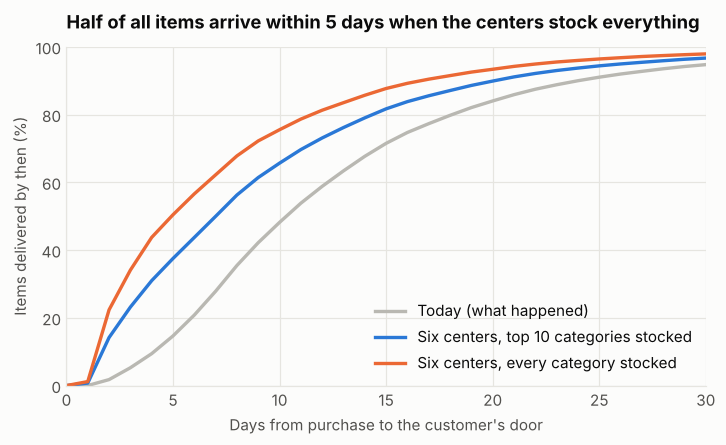

In [6]:
def share_within(days, grid):
    days = np.sort(days[~np.isnan(days)])
    return 100 * np.searchsorted(days, grid, side="right") / len(days)


grid = np.arange(0, 31)
today_days = items["door_days"].to_numpy()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(grid, share_within(today_days, grid), color=COLORS["gray"], linewidth=2.2, label="Today (what happened)")
ax.plot(grid, share_within(items["sim_door_days"].to_numpy(), grid), color=COLORS["blue"], linewidth=2.2,
        label="Six centers, top 10 categories stocked")
ax.plot(grid, share_within(items_all["sim_door_days"].to_numpy(), grid), color=COLORS["orange"], linewidth=2.2,
        label="Six centers, every category stocked")
ax.set_xlabel("Days from purchase to the customer's door")
ax.set_ylabel("Items delivered by then (%)")
ax.set_ylim(0, 100)
ax.set_xlim(0, 30)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Half of all items arrive within 5 days when the centers stock everything")
save_figure(fig, "06_delivery_days.png")
plt.show()

## Step 5. Black Friday

Black Friday fell on 24 November 2017. That day brought 1,341 items, almost six times a normal day, and the week as a whole about two and a half times a normal week. Each center's picking capacity is sized on its average day, so a peak builds a queue. Here is the backlog at each center, in items waiting to be picked at the end of each day.

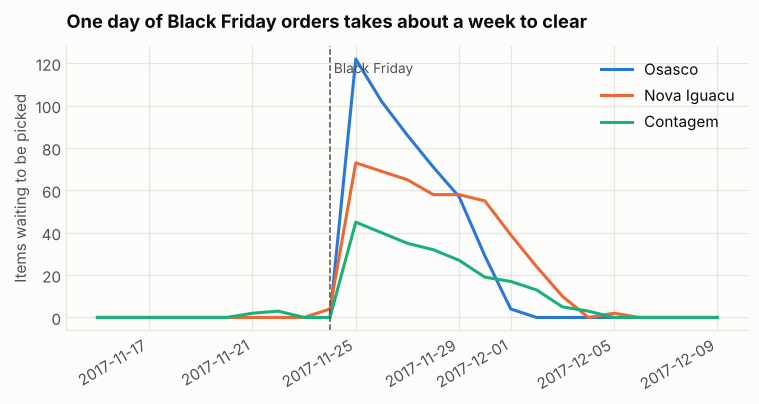

In [7]:
window = daily[(daily["date"] >= "2017-11-15") & (daily["date"] < "2017-12-10")]
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, color in [("osasco, SP", COLORS["blue"]), ("nova iguacu, RJ", COLORS["orange"]),
                    ("contagem, MG", COLORS["aqua"])]:
    w = window[window["center"] == name]
    ax.plot(w["date"], w["backlog"], color=color, linewidth=2, label=name.split(",")[0].title())
ax.axvline(pd.Timestamp("2017-11-24"), color=COLORS["muted"], linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2017-11-24"), ax.get_ylim()[1] * 0.95, " Black Friday", color=COLORS["muted"], fontsize=9, va="top")
ax.set_ylabel("Items waiting to be picked")
ax.legend(frameon=False)
ax.set_title("One day of Black Friday orders takes about a week to clear")
fig.autofmt_xdate()
save_figure(fig, "06_black_friday_backlog.png")
plt.show()

How much spare picking capacity is worth having? Re-run with 10% and 60% headroom and look at delivery times for center orders placed in the two weeks around Black Friday.

In [8]:
def peak_days(items_table):
    peak = items_table[(items_table["ordered"] >= "2017-11-20") & (items_table["ordered"] < "2017-12-04")
                       & (items_table["route"] == "center")]
    return peak["sim_door_days"].mean()


capacity_rows = []
for headroom in [0.10, 0.30, 0.60]:
    it, dl = (items, daily) if headroom == 0.30 else sim.run(data, sim.Settings(capacity_headroom=headroom))
    normal = it[(it["route"] == "center")]["sim_door_days"].mean()
    capacity_rows.append({"picking capacity above average": f"{headroom:.0%}",
                          "largest backlog (items)": int(dl["backlog"].max()),
                          "days to door, center orders, Black Friday weeks": peak_days(it),
                          "days to door, center orders, whole year": normal})
capacity = pd.DataFrame(capacity_rows).set_index("picking capacity above average")
capacity

,largest backlog (items),"days to door, center orders, Black Friday weeks","days to door, center orders, whole year"
picking capacity above average,,,
10%,128,6.42,5.35
30%,122,5.77,4.96
60%,106,5.35,4.84


**What this shows.** Spare picking capacity matters most at the peak. Over the whole year, going from 10% to 60% headroom speeds center orders up by about half a day. In the Black Friday weeks it is well over a day. In practice this is solved with temporary staff for the peak weeks rather than a bigger building, and the simulation says how many: enough to roughly double a center's picking for about a week.

## Step 6. What if suppliers are slower?

Notebook 3 sized safety stock for a one-week lead time. Suppose trucks actually take 5 to 20 days, most often 10, while the policy still assumes one week.

In [9]:
slow_items, _ = sim.run(data, sim.Settings(lead_days=(5, 10, 20)))
slow = sim.summarize(slow_items)
pd.DataFrame({"lead time as assumed (4-12 days)": base, "slower suppliers (5-20 days)": slow}).loc[
    ["fill_rate_pct", "via_center_pct", "door_days_sim", "saving_pct"]]

,lead time as assumed (4-12 days),slower suppliers (5-20 days)
fill_rate_pct,92.93,82.87
via_center_pct,43.88,39.14
door_days_sim,9.39,9.69
saving_pct,7.12,6.42


The fill rate falls from about 93% to 83%, and part of the saving goes with it. The policy is only as good as its lead time assumption. Measuring real supplier lead times would be the first job if this network were built, and safety stock would be resized from them.

## Step 7. Is this just luck?

The simulation draws random transit times and lead times. Run it ten times with different random seeds.

In [10]:
replications = pd.DataFrame([sim.summarize(sim.run(data, sim.Settings(seed=s))[0]) for s in range(10)])
replications[["door_days_sim", "saving_pct", "fill_rate_pct"]].agg(["mean", "std", "min", "max"])

,door_days_sim,saving_pct,fill_rate_pct
mean,9.39,7.09,92.73
std,0.02,0.02,0.32
min,9.37,7.05,92.20
max,9.42,7.13,93.31


Across ten runs, average delivery time varies by about a hundredth of a day and the saving by a few hundredths of a percentage point. With some 78,000 items per run, the randomness averages out, so a single run is enough for the comparisons above.

## What this notebook adds

- **Customers feel a bigger gain than notebook 2 measured.** From purchase to door, delivery falls from 12.7 to 9.4 days, and the share arriving within five days goes from 15% to 37%.
- **The freight saving is smaller than promised, and the reason is a mismatch between two models.** The network model assumed every product would be stocked; the inventory plan stocked ten categories. Only 44% of items go through a center instead of 74%, so the saving is about 7% instead of 11.8%.
- **Stocking everything closes the gap and pays for itself, roughly.** The extra freight saved and the extra inventory cost are about equal. The real return is speed: half of all items within five days.
- **Peaks need people, not buildings.** Black Friday builds a backlog that takes a week to clear. Temporary picking capacity fixes it.
- **Lead time is the assumption to measure first.** Slower suppliers drop the fill rate by ten points.

In [11]:
headline.to_csv(RESULTS / "simulation_headline.csv")
stock_choice.to_csv(RESULTS / "simulation_stock_choice.csv")
capacity.to_csv(RESULTS / "simulation_peak_capacity.csv")
print("Saved results/simulation_*.csv")

Saved results/simulation_*.csv
